# Capacity segmentation with K-Means and PCA

Represent each facility reporting period with one capacity vector, so repeated `Variable` rows do not multiply its clustering weight. Assign each period's cluster to its source reporting rows afterward. Facilities with more reporting periods still contribute more vectors.

The features are log(1 + licensed beds), available/licensed beds, and staffed/available beds. Exclude identities, county codes, and mixed-unit `Amount` from distances. Interpret the clusters as descriptive capacity and resource-availability patterns.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hospital_ml").is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from hospital_ml.data import read_raw, prepare_data, write_json
SEED = 42


In [2]:
from hospital_ml.clustering import run_clustering
frame, audit = prepare_data(read_raw())
summary = run_clustering(frame, ROOT / "reports/clustering", seed=SEED)
display(pd.Series({k: summary[k] for k in ["source_reporting_rows", "facility_periods", "development_facilities", "heldout_facilities", "facility_overlap", "selected_k", "selected_development_silhouette", "heldout_silhouette"]}))

source_reporting_rows              578350.000000
facility_periods                     2690.000000
development_facilities                377.000000
heldout_facilities                     95.000000
facility_overlap                        0.000000
selected_k                              3.000000
selected_development_silhouette         0.407040
heldout_silhouette                      0.444731
dtype: float64

## Selection and validation

Hold out 20% of FAC_NO groups before learning preprocessing or K. On development facilities only, compare K=2..8 using a fixed seeded silhouette sample (up to 2,000 periods), random-seed ARI, and five whole-facility bootstrap refits, including fresh preprocessing. Choose the largest silhouette among candidates with mean bootstrap ARI ≥ 0.80 and minimum cluster share ≥ 2%; otherwise flag unsupported stability/size. This rule is declared in source before evaluation; K=3 is not hardcoded.

Feature clipping uses training 1st/99th percentiles, followed by training-median imputation and standardization. Missing/zero denominators remain missing until imputation. The frozen development K-Means and PCA both consume exactly **`X_cluster_scaled` in the same column order**. PCA is a display projection, not model selection or proof of real groups. Held-out facilities do not choose K, features, or preprocessing.

,k,development_silhouette,development_inertia,min_cluster_fraction,seed_ari_mean,seed_ari_min,facility_bootstrap_ari_mean,facility_bootstrap_ari_std,facility_bootstrap_ari_min,facility_bootstrap_ari_values
0,2,0.350764,4660.326975,0.275766,1.000000,1.000000,0.364404,0.505576,-0.048993,"[-0.04899331363143127, -0.04764032713352695, 0..."
1,3,0.407040,3012.510743,0.107242,1.000000,1.000000,0.964743,0.014134,0.946417,"[0.9511536593659671, 0.9673722510317876, 0.974..."
2,4,0.379751,2164.042318,0.103528,0.999267,0.998533,0.900666,0.030395,0.859384,"[0.8921499207097908, 0.8593840734559679, 0.952..."
3,5,0.341933,1854.916719,0.101671,0.997499,0.994999,0.755333,0.129836,0.554836,"[0.8179572432980295, 0.6681352843258068, 0.807..."
4,6,0.349562,1610.531595,0.044568,0.996489,0.992982,0.786056,0.092334,0.631677,"[0.8234472046031502, 0.7489047543698396, 0.817..."
5,7,0.319800,1438.146956,0.042247,0.811424,0.723000,0.508287,0.088125,0.416316,"[0.4893496572883135, 0.41631576680810695, 0.55..."
6,8,0.341921,1280.951245,0.017642,0.967795,0.942192,0.624313,0.188237,0.380530,"[0.38052957457509423, 0.6199016146310634, 0.79..."


Selection requirements supported: True
PCA explained variance: [0.3975719084783235, 0.3449082791106213]
ARI versus no feature clipping (development only): 0.991456992610671


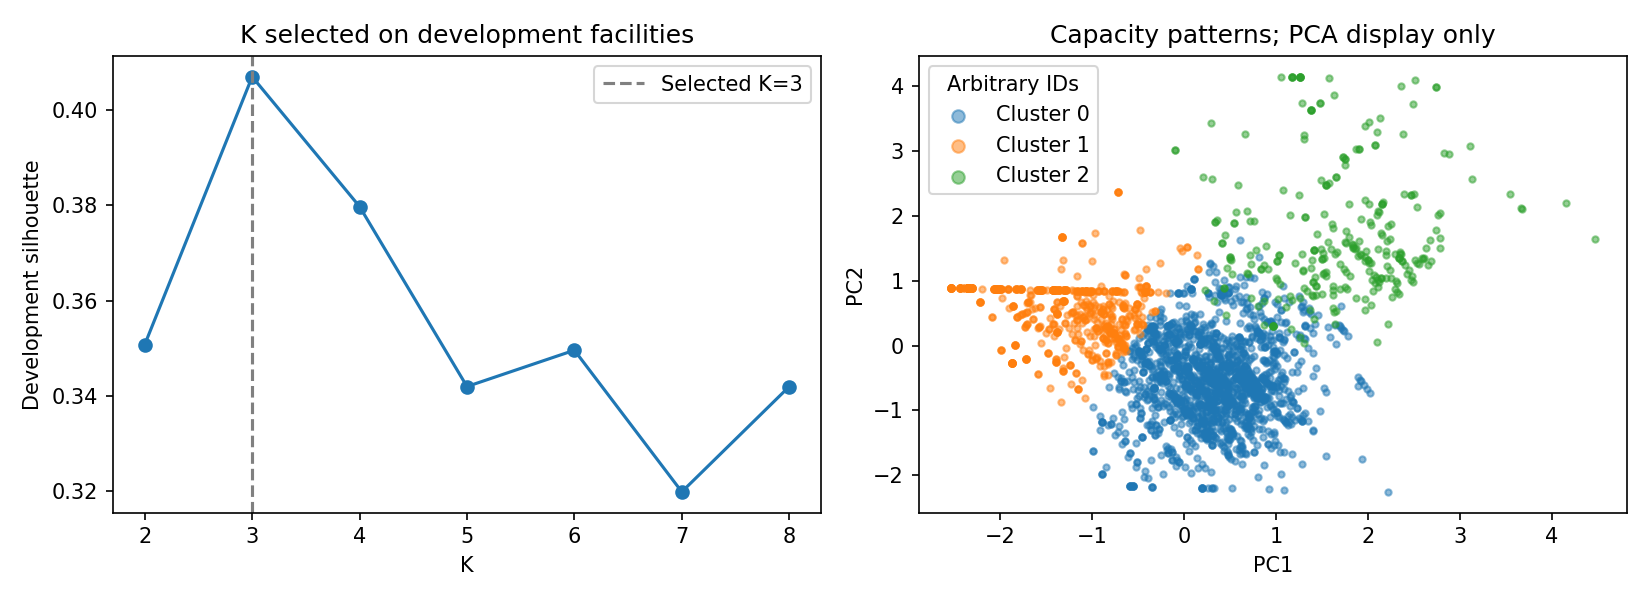

In [3]:
selection = pd.read_csv(ROOT / "reports/clustering/k_selection.csv")
display(selection)
print("Selection requirements supported:", summary["selection_stability_size_supported"])
print("PCA explained variance:", summary["pca_explained_variance_ratio"])
print("ARI versus no feature clipping (development only):", summary["development_ari_without_clipping_at_selected_k"])
display(Image(filename=str(ROOT / "reports/clustering/capacity_clusters.png")))

In [4]:
profiles = pd.read_csv(ROOT / "reports/clustering/cluster_profiles.csv")
display(profiles)
display(pd.read_csv(ROOT / "reports/clustering/pca_loadings.csv"))
print(summary["interpretation"])
for limitation in summary["limitations"]:
    print("-", limitation)

,split,resource_cluster,BED_LIC_median,BED_LIC_q25,BED_LIC_q75,BED_AVL_median,BED_AVL_q25,BED_AVL_q75,BED_STF_median,BED_STF_q25,BED_STF_q75,available_share_median,available_share_q25,available_share_q75,staffed_share_median,staffed_share_q25,staffed_share_q75,facility_periods,unique_facilities,reporting_rows
0,development,0,214.0,120.00,350.00,213.0,117.0,347.0,127.0,61.0,223.0,1.000000,1.000000,1.000000,0.592254,0.478131,0.692572,1367,283,293905
1,development,1,46.0,19.25,84.00,46.0,23.0,84.0,37.0,17.0,74.0,1.000000,1.000000,1.000000,1.000000,0.854804,1.000000,556,129,119540
2,development,2,258.0,83.00,478.50,205.0,63.5,363.0,143.0,42.0,246.5,0.757576,0.688883,0.807692,0.680000,0.560392,0.870663,231,72,49665
3,heldout_facility,0,222.0,137.00,345.00,211.0,133.0,343.0,119.0,70.0,214.0,1.000000,1.000000,1.000000,0.576389,0.472222,0.715640,313,64,67295
4,heldout_facility,1,47.0,16.00,91.00,48.0,16.0,91.0,42.0,16.0,72.0,1.000000,1.000000,1.000000,0.955224,0.827586,1.000000,169,40,36335
5,heldout_facility,2,403.0,138.75,461.25,303.0,115.0,348.5,179.5,72.0,243.5,0.757622,0.667172,0.798488,0.704507,0.551530,0.805850,54,17,11610


,feature,PC1,PC2
0,log_licensed_beds,0.735527,-0.022783
1,available_share,-0.521495,-0.657037
2,staffed_share,-0.432485,0.753514


Capacity/resource-availability patterns, not hospital efficiency, clinical quality, staffing headcount, or causal optimization. Amount is excluded because Variable mixes units.
- Facility-periods from the same facility are correlated; facility-separated diagnostics and resampling reduce this dependence but do not establish temporal forecasting.
- Each facility-period has equal fitting weight; facilities with more reporting periods contribute more vectors. Long Variable rows do not multiply fitting weight.
- Five facility bootstraps provide sensitivity evidence, not a confidence interval or proof of a natural population partition.
- K=2..8 is a prespecified finite search; silhouette favors some geometries and must be read with stability and profiles.
- All periods receive the frozen development model; PCA and cluster IDs carry no ordering or efficiency meaning.
- Capacity-only features cannot distinguish financial resource intensity or patient case mix.
- Licensed beds are end-of-period

## Interpretation

Use medians and interquartile ranges to describe capacity profiles. Cluster numbers are arbitrary. Availability shares combine period-average bed measures with an end-period licensed count; values above one require reporting-context review.

Clipping sensitivity and bootstrap stability describe how the grouping responds to methodological choices. They do not validate hospital efficiency or optimization decisions. Every period receives a label from the model fitted on development facilities.